# Phase 3 : analyse des règles et de la signature pré-éruption

Entrées : les règles FP-Growth extraites dans Weka (`weka/results/`) et les transactions de la phase 1.

Critères : uniquement le **support** et la **confiance** du cours. Une règle X → Y est jugée informative si conf(X → Y) > supp(Y), c'est-à-dire si la présence de X rend Y plus fréquent qu'en moyenne (ce rapport conf/supp(Y) est ce qu'on appelle ailleurs le *lift*).

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.analyse import (
    parse_weka_rules, load_transactions, add_measures, filter_informative, remove_redundant,
    rules_with_items, pre_event_window, common_itemset, rules_verified_by, itemset_support,
    yearly_counts, trend_test, plot_yearly,
)
from src.preparation import load_power_csv

pd.set_option('display.max_colwidth', 100)

RESULTS = ROOT / 'weka' / 'results'
FIGURES = ROOT / 'results' / 'figures'
tx = load_transactions(ROOT / 'data' / 'processed' / 'transactions.csv')

def show(rules, n=10):
    """Affichage lisible d'un tableau de règles."""
    out = rules.head(n).copy()
    out['premise'] = out['premise'].map(lambda s: ', '.join(sorted(s)))
    out['consequent'] = out['consequent'].map(lambda s: ', '.join(sorted(s)))
    return out[['premise', 'consequent', 'supp', 'conf', 'supp_consequent', 'gain']].round(3)

## 1. Les trois essais FP-Growth

minConf = 0,7 ; minSupp = 0,10, 0,05 et 0,01. Pour chaque essai : nombre de règles brutes, puis après filtrage :
- **informatives** : conf(X → Y) > supp(Y) ;
- **non redondantes** : on retire X → Y s'il existe X' ⊂ X avec X' → Y et une confiance au moins égale (ajouter un item à la prémisse sans gagner en confiance n'apporte rien, cas typique de `Tmin_Warm`).

In [2]:
runs = {}
summary = []
for s in ['010', '005', '001']:
    rules = add_measures(parse_weka_rules(RESULTS / f'fpgrowth_s{s}_c070.txt'), tx)
    informative = filter_informative(rules)
    clean = remove_redundant(informative)
    runs[s] = clean
    summary.append({'minSupp': int(s) / 100, 'règles Weka': len(rules),
                    'informatives': len(informative), 'non redondantes': len(clean)})
pd.DataFrame(summary)

,minSupp,règles Weka,informatives,non redondantes
0,0.10,572,536,203
1,0.05,783,735,229
2,0.01,1572,1496,407


## 2. Où apparaissent les items extrêmes ?

À minSupp = 0,10 et 0,05, aucun item extrême n'apparaît : d'après l'anti-monotonie du support, un motif qui contient un item de support ≤ 4 % a lui-même un support ≤ 4 %. On travaille donc sur l'essai à **0,01**. `Tmin_Severe_Cooling` (16 jours) et `Wind_High_Shear` (5 jours) ne peuvent apparaître dans aucune règle (support < 0,01, soit 153 jours).

In [3]:
rules = runs['001']
EXTREMES = ['Rain_Extreme_Downpour', 'Pressure_Critical_Drop', 'Tmin_Cold', 'DTR_Extreme',
            'Tmin_Severe_Cooling', 'Wind_High_Shear']
pd.Series({it: len(rules_with_items(rules, [it])) for it in EXTREMES}, name='règles (0,01, filtrées)')

Rain_Extreme_Downpour     29
Pressure_Critical_Drop    22
Tmin_Cold                 31
DTR_Extreme               16
Tmin_Severe_Cooling        0
Wind_High_Shear            0
Name: règles (0,01, filtrées), dtype: int64

Règles les plus marquées (écart conf − supp(Y) le plus grand) pour chaque item extrême :

In [4]:
for it in ['Rain_Extreme_Downpour', 'Pressure_Critical_Drop', 'Tmin_Cold', 'DTR_Extreme']:
    print(it)
    display(show(rules_with_items(rules, [it]).sort_values('gain', ascending=False), 5))

Rain_Extreme_Downpour


,premise,consequent,supp,conf,supp_consequent,gain
13,"Rain_Extreme_Downpour, Wind_Moderate","DTR_Suppressed, Season_Monsoon_Peak",0.013,0.94,0.386,0.554
14,"Rain_Extreme_Downpour, Wind_Moderate","DTR_Suppressed, Season_Monsoon_Peak, Tmin_Warm",0.013,0.94,0.386,0.554
6,"DTR_Suppressed, Rain_Extreme_Downpour, Wind_Moderate","Season_Monsoon_Peak, Tmin_Warm",0.013,0.97,0.462,0.508
5,"DTR_Suppressed, Rain_Extreme_Downpour, Wind_Moderate",Season_Monsoon_Peak,0.013,0.97,0.463,0.507
19,"Pressure_High_Stable, Rain_Extreme_Downpour","DTR_Suppressed, Season_Monsoon_Peak",0.010,0.89,0.386,0.504


Pressure_Critical_Drop


,premise,consequent,supp,conf,supp_consequent,gain
5,"Pressure_Critical_Drop, Rain_Moderate, Wind_Calm","Season_Transition, Tmin_Warm",0.015,0.87,0.246,0.624
4,"Pressure_Critical_Drop, Rain_Moderate, Wind_Calm",Season_Transition,0.015,0.87,0.246,0.624
10,"Pressure_Critical_Drop, Rain_Moderate","Season_Transition, Tmin_Warm",0.018,0.83,0.246,0.584
9,"Pressure_Critical_Drop, Rain_Moderate",Season_Transition,0.018,0.83,0.246,0.584
15,"DTR_Suppressed, Pressure_Critical_Drop","Season_Transition, Tmin_Warm",0.010,0.80,0.246,0.554


Tmin_Cold


,premise,consequent,supp,conf,supp_consequent,gain
7,"Tmin_Cold, Wind_Moderate","Rain_None, Season_Dry",0.038,0.97,0.255,0.715
1,"DTR_Moderate, Rain_None, Tmin_Cold",Season_Dry,0.039,1.00,0.291,0.709
0,"DTR_Moderate, Pressure_Normal, Tmin_Cold",Season_Dry,0.032,1.00,0.291,0.709
3,"DTR_Moderate, Tmin_Cold, Wind_Moderate",Season_Dry,0.031,1.00,0.291,0.709
4,"Pressure_Normal, Tmin_Cold, Wind_Moderate",Season_Dry,0.030,1.00,0.291,0.709


DTR_Extreme


,premise,consequent,supp,conf,supp_consequent,gain
4,"DTR_Extreme, Tmin_Warm","Rain_None, Wind_Moderate",0.011,0.92,0.186,0.734
5,"DTR_Extreme, Pressure_Normal","Rain_None, Wind_Moderate",0.016,0.91,0.186,0.724
6,DTR_Extreme,"Rain_None, Wind_Moderate",0.020,0.90,0.186,0.714
9,"DTR_Extreme, Rain_None","Season_Dry, Wind_Moderate",0.017,0.82,0.169,0.651
11,DTR_Extreme,"Rain_None, Season_Dry, Wind_Moderate",0.017,0.80,0.158,0.642


**Lecture.** Chaque facteur « de risque » de l'énoncé est lié à une saison différente :
- les **pluies extrêmes** vont avec la mousson, un ciel couvert (DTR faible) et des nuits douces ;
- les **chutes de pression critiques** vont avec la saison de transition (mars–mai) ;
- les **nuits froides** et les **fortes amplitudes thermiques** vont avec la saison sèche, sans pluie.

Ces conditions ne se combinent donc presque jamais : la signature composite de l'énoncé (chute de pression + choc thermique + pluie orageuse) est quasi absente des données.

In [5]:
composites = {
    'Pression critique + pluie extrême': ['Pressure_Critical_Drop', 'Rain_Extreme_Downpour'],
    'Pression critique + nuit froide': ['Pressure_Critical_Drop', 'Tmin_Cold'],
    'Pluie extrême + nuit froide': ['Rain_Extreme_Downpour', 'Tmin_Cold'],
    'Les trois ensemble': ['Pressure_Critical_Drop', 'Rain_Extreme_Downpour', 'Tmin_Cold'],
}
pd.Series({k: int(round(itemset_support(tx, v) * len(tx))) for k, v in composites.items()}, name='jours (1983–2024)')

Pression critique + pluie extrême     6
Pression critique + nuit froide      16
Pluie extrême + nuit froide           1
Les trois ensemble                    0
Name: jours (1983–2024), dtype: int64

## 3. La fenêtre pré-éruption

L'éruption a eu lieu le 15 août 1984 (DOY 228). On prend les **7 jours** qui se terminent le jour de l'éruption (DOY 222 à 228).

In [6]:
window = pre_event_window(tx, year=1984, doy_event=228, n_days=7)
window

,YEAR,DOY,Season,Rain,Tmin,DTR,Wind,Pressure
586,1984,222,Season_Monsoon_Peak,Rain_Moderate,Tmin_Warm,DTR_Suppressed,Wind_Moderate,Pressure_Normal
587,1984,223,Season_Monsoon_Peak,Rain_Moderate,Tmin_Warm,DTR_Moderate,Wind_Calm,Pressure_Normal
588,1984,224,Season_Monsoon_Peak,Rain_Moderate,Tmin_Warm,DTR_Moderate,Wind_Calm,Pressure_Normal
589,1984,225,Season_Monsoon_Peak,Rain_Moderate,Tmin_Warm,DTR_Suppressed,Wind_Calm,Pressure_Normal
590,1984,226,Season_Monsoon_Peak,Rain_Moderate,Tmin_Warm,DTR_Suppressed,Wind_Calm,Pressure_Normal
591,1984,227,Season_Monsoon_Peak,Rain_Moderate,Tmin_Warm,DTR_Suppressed,Wind_Calm,Pressure_Normal
592,1984,228,Season_Monsoon_Peak,Rain_Moderate,Tmin_Warm,DTR_Suppressed,Wind_Calm,Pressure_Normal


Aucun item extrême sur ces 7 jours : ce sont des journées de mousson ordinaires.

## 4. La signature observée

La signature est le motif présent **tous les jours** de la fenêtre, et les règles (essai à 0,01, filtrées) vérifiées chaque jour.

In [7]:
signature = common_itemset(window)
print('Signature :', sorted(signature))
print(f'Support sur 1983–2024 : {itemset_support(tx, signature):.3f}')

Signature : ['Pressure_Normal', 'Rain_Moderate', 'Season_Monsoon_Peak', 'Tmin_Warm']
Support sur 1983–2024 : 0.233


In [8]:
show(rules_verified_by(rules, window).sort_values('gain', ascending=False), 20)

,premise,consequent,supp,conf,supp_consequent,gain
4,Season_Monsoon_Peak,"Rain_Moderate, Tmin_Warm",0.395,0.85,0.618,0.232
3,Season_Monsoon_Peak,Rain_Moderate,0.395,0.85,0.619,0.231
1,Rain_Moderate,Tmin_Warm,0.618,1.00,0.949,0.051
0,Season_Monsoon_Peak,Tmin_Warm,0.462,1.00,0.949,0.051
5,Tmin_Warm,Pressure_Normal,0.689,0.73,0.728,0.002
2,Pressure_Normal,Tmin_Warm,0.689,0.95,0.949,0.001


La signature est un motif fréquent (support ≈ 0,23, soit environ un jour sur quatre). Les règles qu'elle vérifie décrivent la mousson ordinaire : en pic de mousson, la pluie est le plus souvent modérée et les nuits douces.

## 5. Fréquence de réapparition de la signature (1983–2024)

slope_days_per_year      -1.0216
slope_days_per_decade   -10.2155
linreg_pvalue             0.0000
kendall_tau              -0.4426
mann_kendall_pvalue       0.0000
dtype: float64

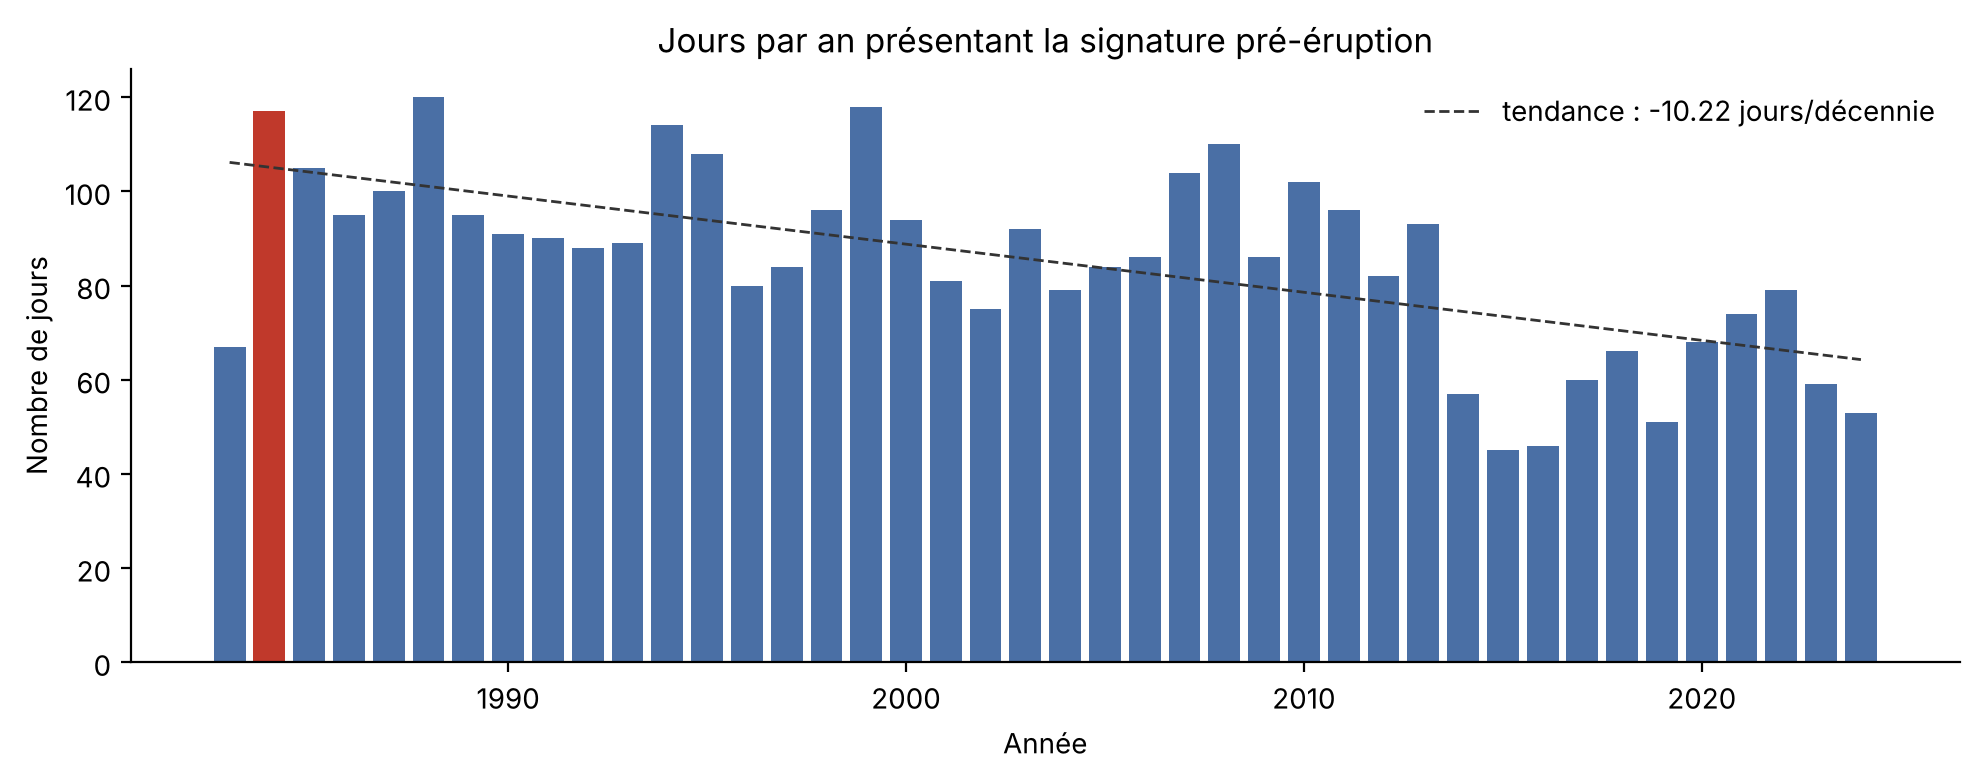

In [9]:
sig_counts = yearly_counts(tx, signature)
fig = plot_yearly(sig_counts, 'Jours par an présentant la signature pré-éruption',
                  FIGURES / 'signature_par_an.png')
trend_test(sig_counts).round(4)

La signature devient **moins fréquente** : environ −10 jours par décennie, tendance significative (Mann-Kendall, p < 0,001). La baisse se concentre après 2013. La section 7 en cherche la cause.

## 6. Fréquence des facteurs extrêmes de l'énoncé

,item,jours (total),jours en 1984,pente (jours/décennie),p Mann-Kendall
0,Rain_Extreme_Downpour,637,9,3.305,0.292
1,Pressure_Critical_Drop,630,50,-3.891,0.014
2,Tmin_Cold,767,42,-3.265,0.031
3,DTR_Extreme,334,0,3.045,0.036


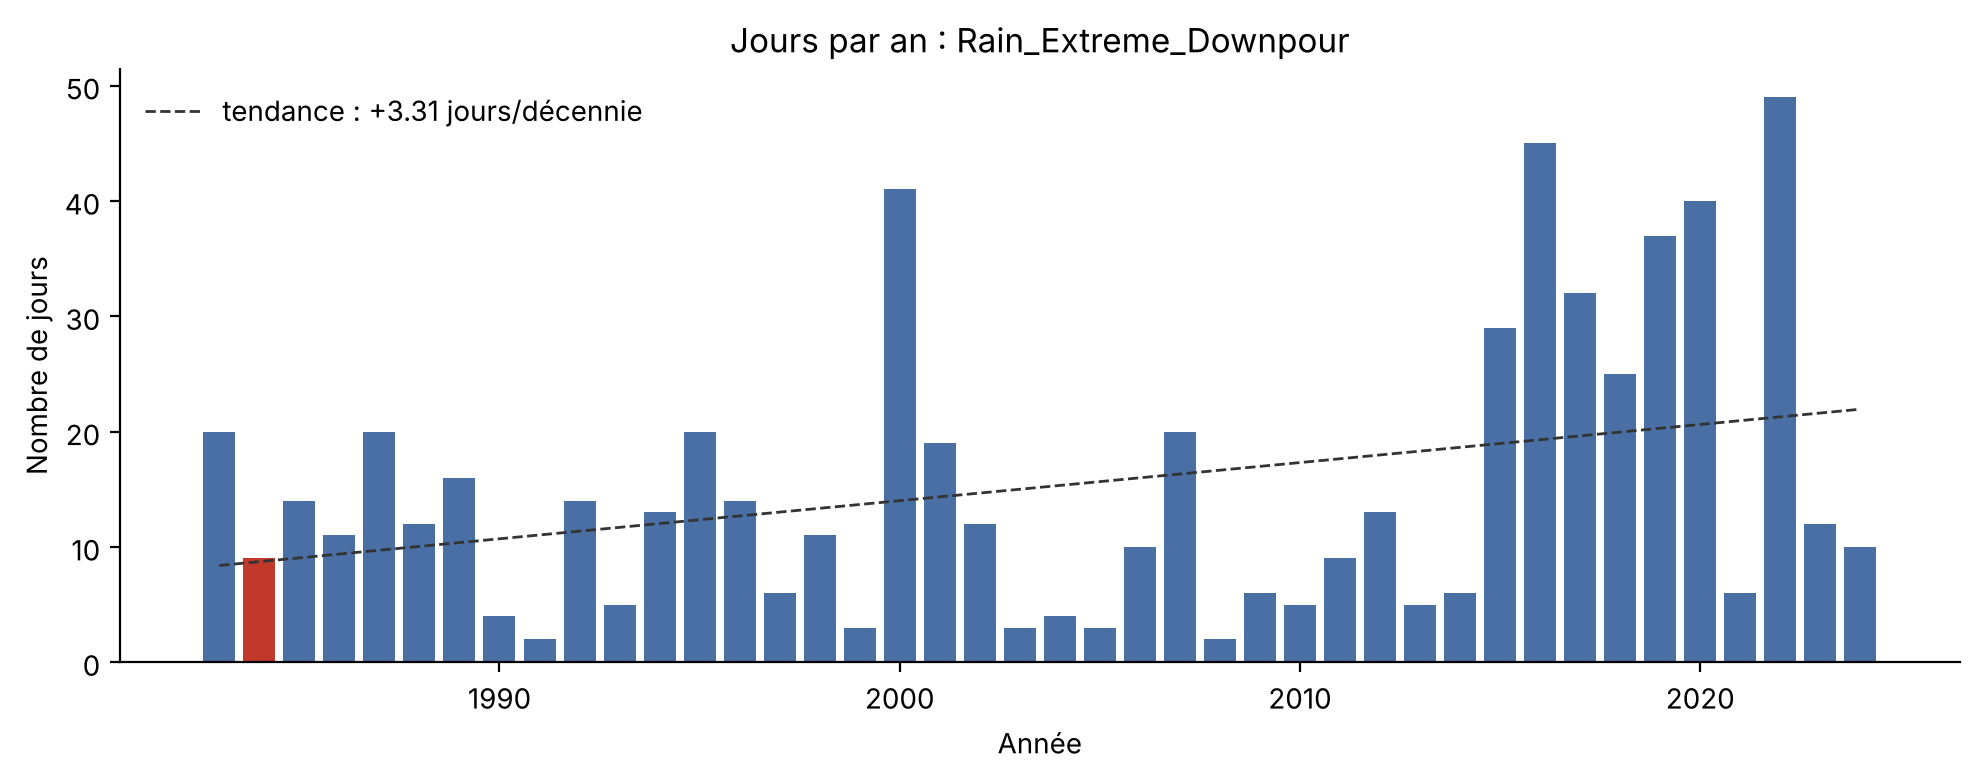

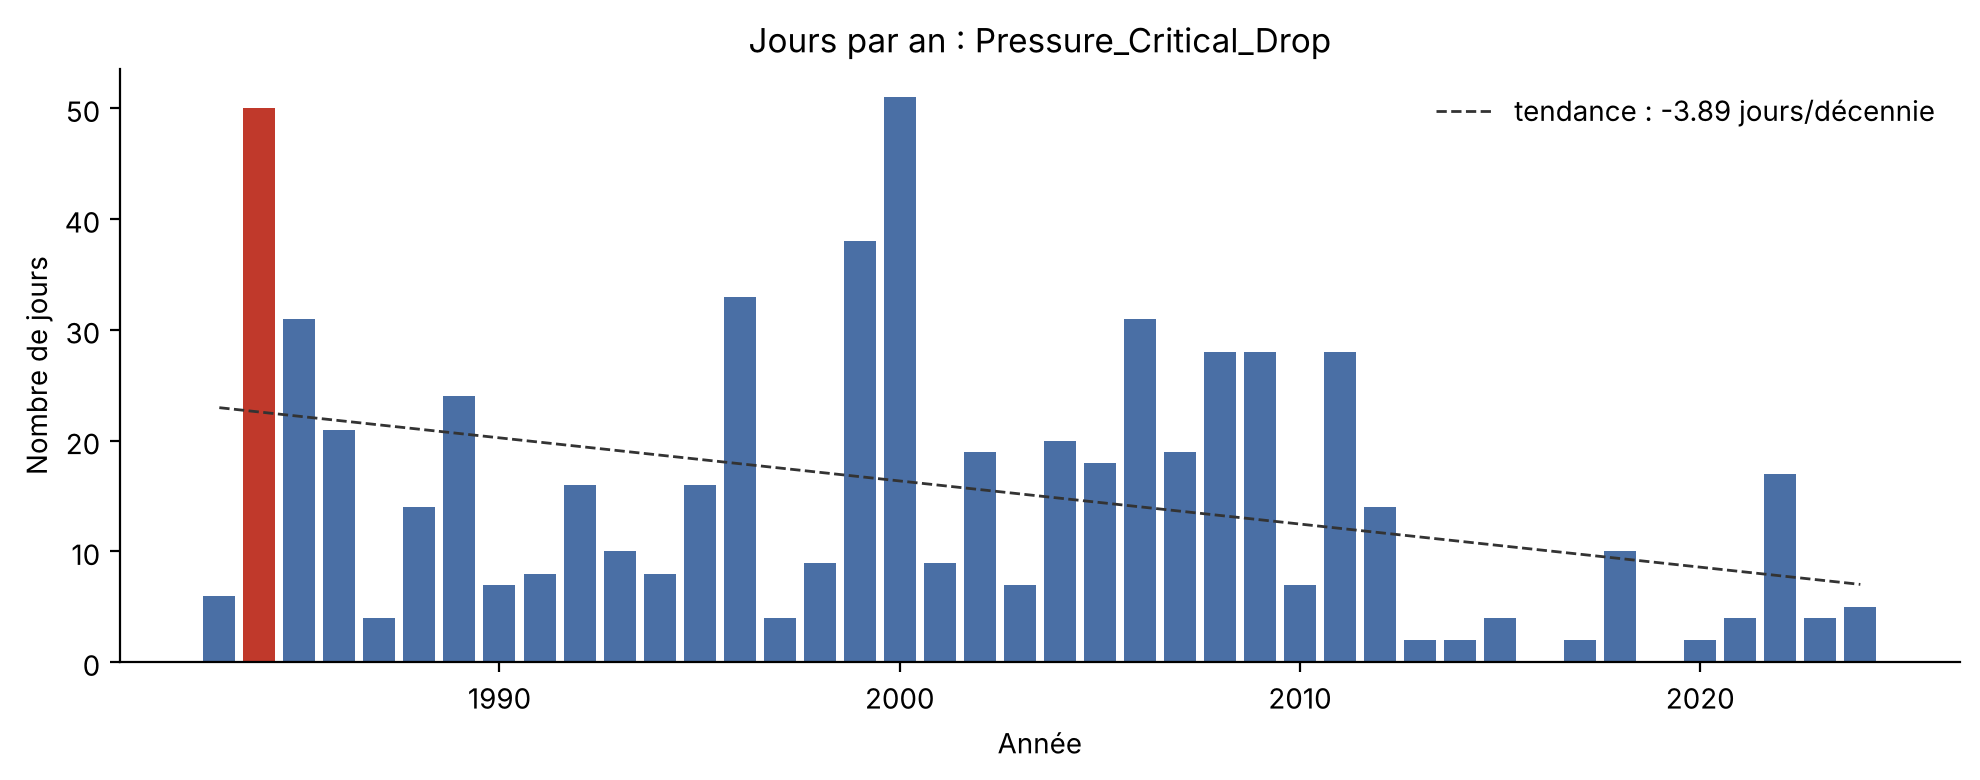

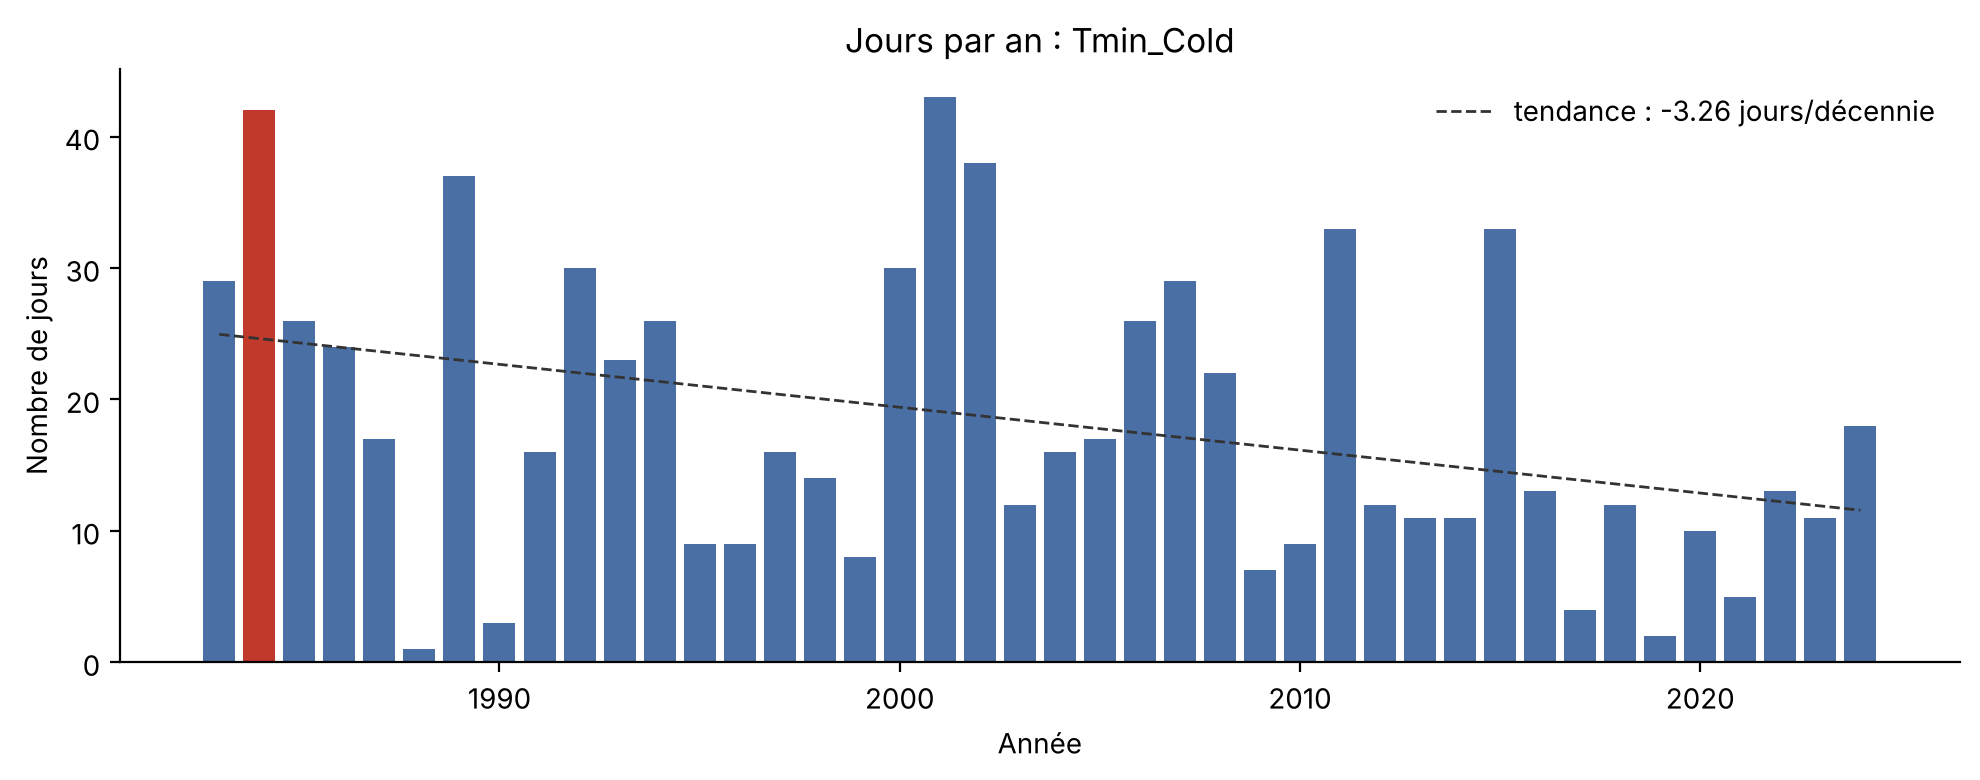

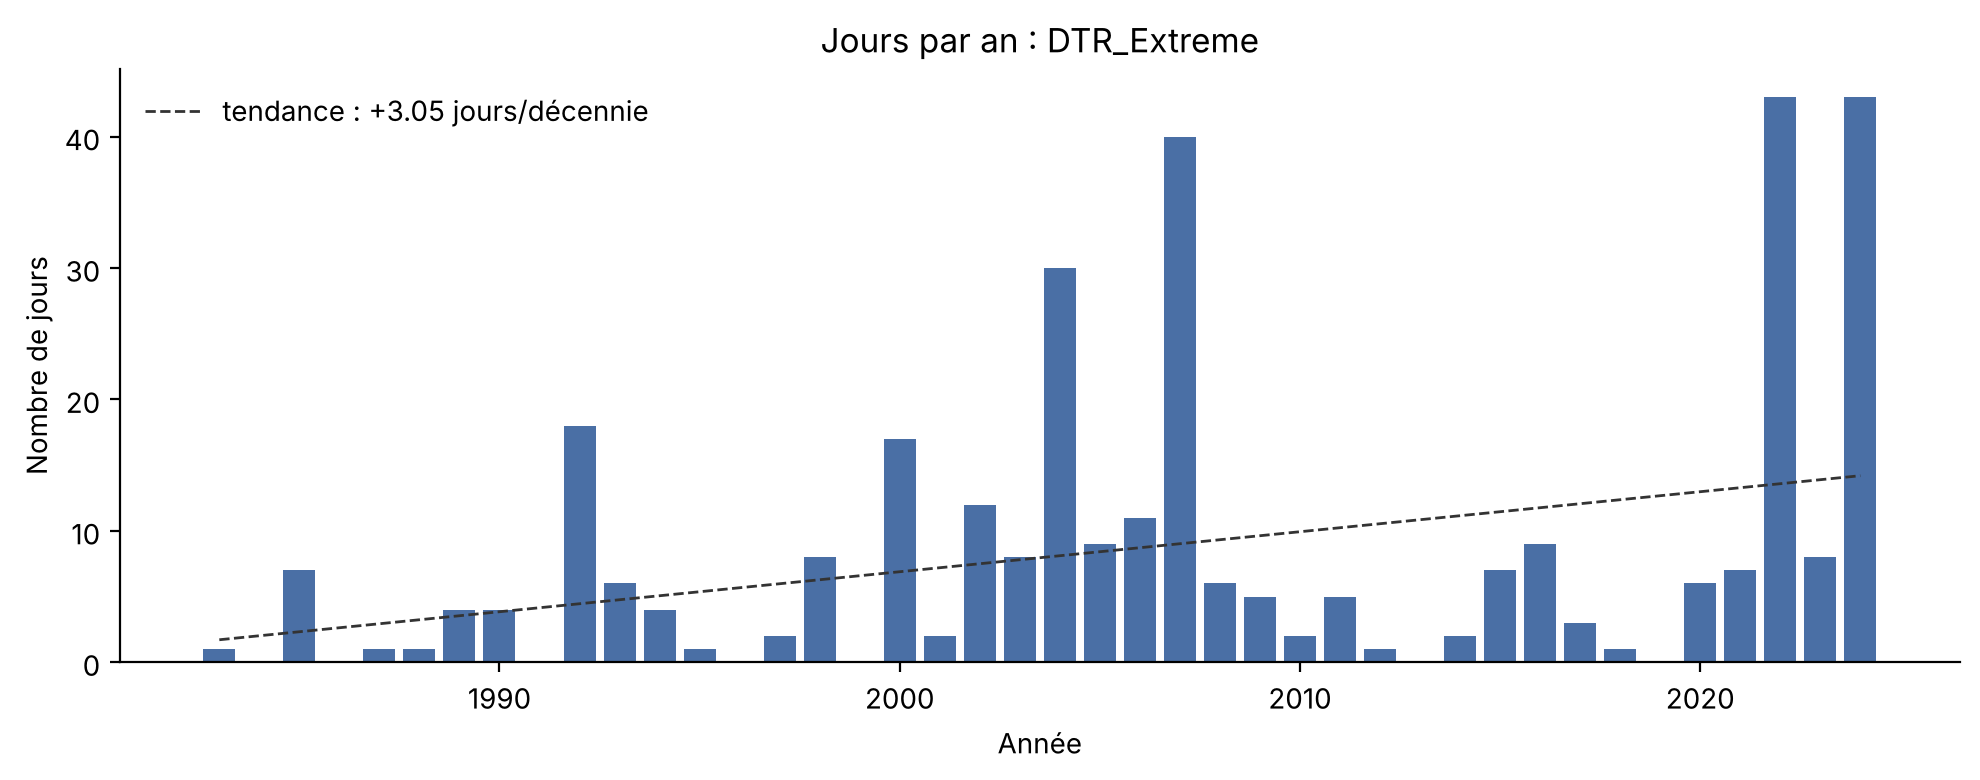

In [10]:
trends = []
for it in ['Rain_Extreme_Downpour', 'Pressure_Critical_Drop', 'Tmin_Cold', 'DTR_Extreme']:
    c = yearly_counts(tx, [it])
    plot_yearly(c, f'Jours par an : {it}', FIGURES / f'{it}_par_an.png')
    t = trend_test(c)
    trends.append({'item': it, 'jours (total)': c.sum(), 'jours en 1984': c.loc[1984],
                   'pente (jours/décennie)': t.slope_days_per_decade, 'p Mann-Kendall': t.mann_kendall_pvalue})
pd.DataFrame(trends).round(3)

Au seuil de 5 % : les nuits froides et les chutes de pression critiques **diminuent**, les fortes amplitudes thermiques **augmentent**, la hausse des pluies extrêmes n'est pas significative. La baisse des nuits froides est cohérente avec le réchauffement (la Tmin moyenne passe d'environ 16,5–16,7 °C dans les années 1980 à environ 17,5 °C dans les années 2020).

## 7. Pourquoi la signature recule après 2013 ?

En pic de mousson, la pression moyenne est très proche du seuil de 88,7 kPa qui sépare `Pressure_Normal` de `Pressure_High_Stable`. Un faible décalage suffit donc à faire basculer de nombreux jours d'une classe à l'autre.

In [11]:
raw = load_power_csv(ROOT / 'data' / 'raw' / 'LAC_MONOUN_POWER_Daily_1983-2024.csv')
monsoon = tx[tx['Season'] == 'Season_Monsoon_Peak']
ps = raw[raw['DOY'].between(151, 319)].groupby('YEAR')['PS'].mean()
by_year = pd.crosstab(monsoon['YEAR'], monsoon['Pressure']).join(
    pd.crosstab(monsoon['YEAR'], monsoon['Rain'])[['Rain_Extreme_Downpour']])
by_year['PS moyenne (kPa)'] = ps.round(3)
by_year.loc[2008:2018]

,Pressure_Critical_Drop,Pressure_High_Stable,Pressure_Normal,Rain_Extreme_Downpour,PS moyenne (kPa)
YEAR,,,,,
2008,0,41,128,2,88.649
2009,0,77,92,4,88.682
2010,1,59,109,5,88.660
2011,1,55,113,9,88.649
2012,0,82,87,12,88.697
2013,0,70,99,5,88.691
2014,0,105,64,6,88.725
2015,0,108,61,28,88.733
2016,0,100,69,33,88.719


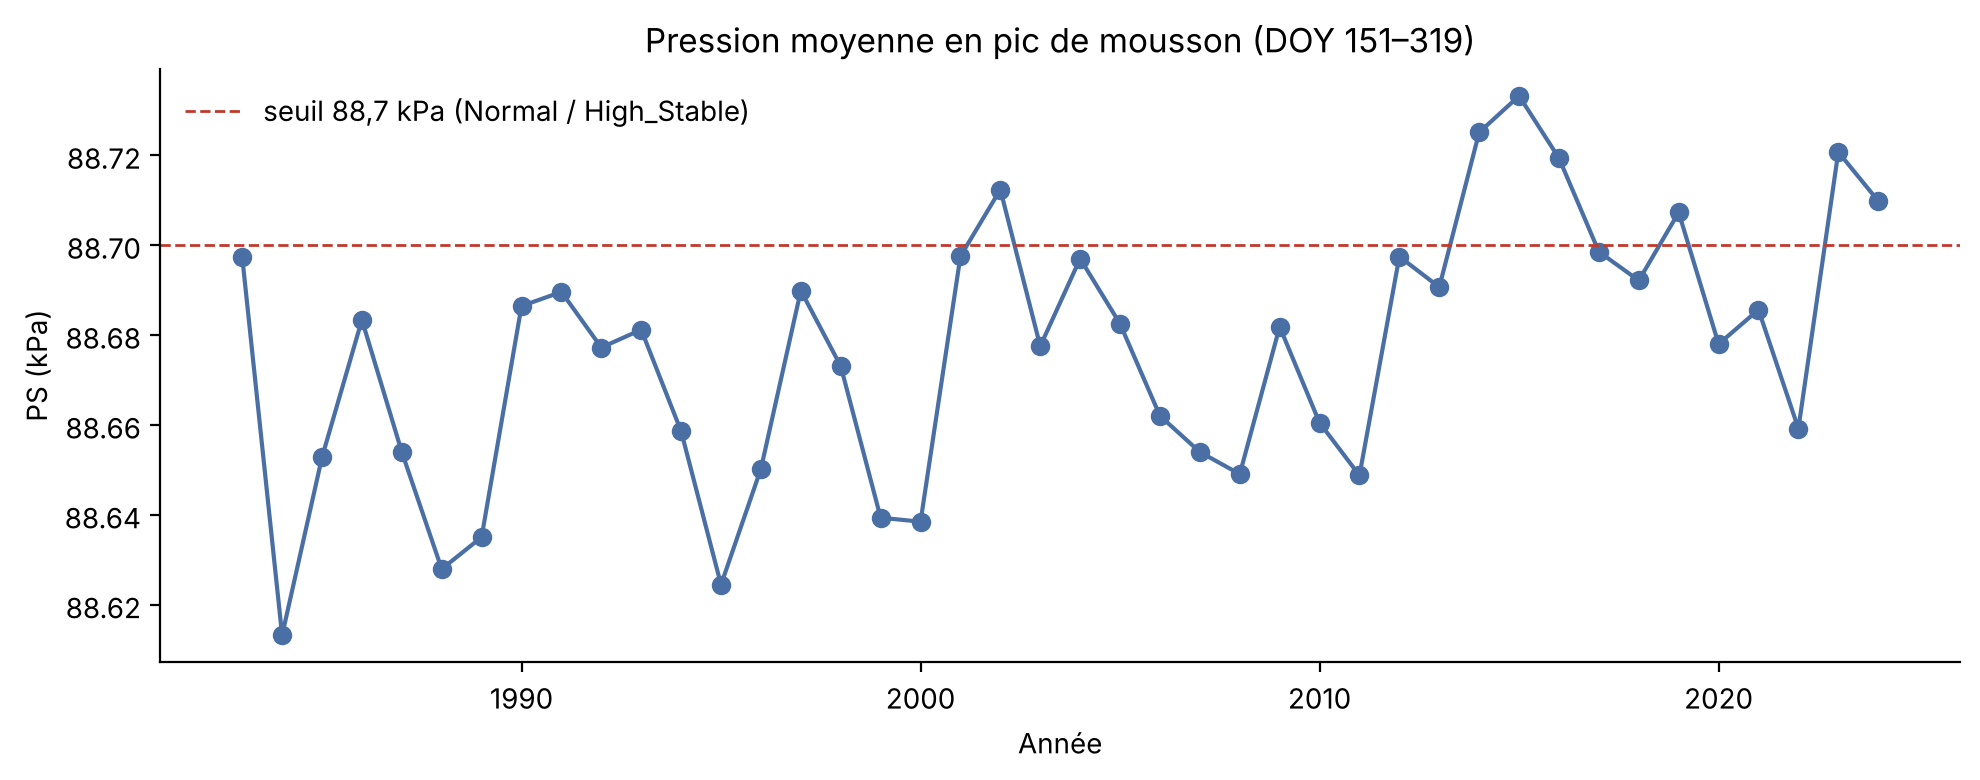

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ps.index, ps.values, marker='o', color='#4a6fa5')
ax.axhline(88.7, color='#c0392b', linestyle='--', linewidth=1, label='seuil 88,7 kPa (Normal / High_Stable)')
ax.set_title('Pression moyenne en pic de mousson (DOY 151–319)')
ax.set_xlabel('Année')
ax.set_ylabel('PS (kPa)')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / 'pression_mousson_par_an.png', dpi=150)

Deux effets expliquent le recul de la signature après 2013 :
- **la pression** : la moyenne de mousson passe de 88,667 kPa (1983–2013) à 88,703 kPa (2014–2024), soit +0,04 kPa, ce qui la place au niveau du seuil de 88,7 kPa. De nombreux jours deviennent `Pressure_High_Stable` et sortent de la signature ;
- **les pluies extrêmes de mousson** : de 9,5 jours/an en moyenne (1983–2013) à 22,5 jours/an (2014–2024). Ces jours remplacent `Rain_Moderate` et sortent eux aussi de la signature.

L'effet pression est un **décalage très faible situé juste sur un seuil** : le comptage est donc sensible au choix de 88,7 kPa. La hausse des pluies extrêmes en mousson est un signal plus net, même si la tendance des pluies extrêmes sur l'année entière n'est pas significative (section 6).

## 8. Conclusions et limites

**Conclusions (seuils de l'énoncé, minSupp = 0,01, minConf = 0,7)**
1. Les facteurs « de risque » de l'énoncé relèvent de saisons différentes : pluies extrêmes en mousson, chutes de pression en transition, nuits froides en saison sèche. Leur combinaison est quasi inexistante (0 jour pour les trois ensemble en 42 ans).
2. Les 7 jours précédant l'éruption du 15 août 1984 ne présentent **aucun** item extrême. Leur signature commune est {Season_Monsoon_Peak, Rain_Moderate, Tmin_Warm, Pressure_Normal}, un motif fréquent de la mousson ordinaire (≈ 1 jour sur 4).
3. Cette signature devient moins fréquente (≈ −10 jours/décennie), surtout après 2013, sous l'effet d'une légère hausse de la pression de mousson (au niveau du seuil de 88,7 kPa) et de pluies extrêmes plus fréquentes en mousson.
4. Les nuits froides diminuent et les fortes amplitudes thermiques augmentent, ce qui est cohérent avec le réchauffement.

Les données ne soutiennent donc pas l'hypothèse d'un déclenchement par un événement météo extrême composite. Ce résultat est compatible avec l'hypothèse d'un déclencheur interne au lac (saturation progressive en CO₂, glissement de terrain…), que ces données ne permettent pas de tester.

**Limites**
- **Un seul événement** : la signature repose sur 7 jours ; on ne peut pas valider statistiquement une signature de risque avec un seul cas.
- **Réanalyse MERRA-2** : moyenne sur une maille d'environ 50 km, qui lisse les extrêmes locaux (orages, rafales, refroidissement de surface du lac).
- **Seuils fixes** : plusieurs seuils ne correspondent pas aux centiles annoncés (P10 réel de Tmin = 14,9 °C et non 11 °C), et le seuil de pression de 88,7 kPa tombe sur la moyenne de mousson, ce qui rend les comptages sensibles.
- **Règles d'association = co-occurrence** : elles ne montrent pas de causalité.
- **Tests de tendance** : le test de Mann-Kendall suppose des années indépendantes ; une autocorrélation éventuelle n'est pas prise en compte.